In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 120)

### Konfigurasi direktori output dan gaya visualisasi

In [3]:
# Folder output dipisahkan
os.makedirs('Output Transactions', exist_ok=True)
os.makedirs('Output Transactions/Charts', exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY_BLUE = '#2B90B6'
ACCENT_ORANGE = '#E8833A'
DARK_SLATE = '#1E293B'
MUTED_GRAY = '#94A3B8'
DANGER_RED = '#DC2626'
SUCCESS_GREEN = '#10B981'

print('Output Transactions: khusus transactions.xlsx')


Output Transactions: khusus transactions.xlsx


# Dataset Transactions.xlsx

### Dataset transactions.xlsx_sheet transactions

In [4]:
print("Dataset transactions.xlsx")

excel_path = 'transactions.xlsx'
if not os.path.exists(excel_path):
    raise FileNotFoundError(
        f"File '{excel_path}' tidak ditemukan. Pastikan file berada di folder."
    )

xls = pd.ExcelFile(excel_path)
print(f"Sheet dalam {excel_path}: {xls.sheet_names}")

required_sheets = {'transactions', 'customer'}
missing_sheets = required_sheets.difference(xls.sheet_names)
if missing_sheets:
    raise ValueError(f"Sheet tidak ditemukan: {sorted(missing_sheets)}")

df_trans = pd.read_excel(excel_path, sheet_name='transactions')
df_cust = pd.read_excel(excel_path, sheet_name='customer')

print("Ukuran data transaksi:", df_trans.shape)
print("Ukuran data pelanggan:", df_cust.shape)


Dataset transactions.xlsx
Sheet dalam transactions.xlsx: ['transactions', 'customer']
Ukuran data transaksi: (7511, 11)
Ukuran data pelanggan: (76637, 7)


In [5]:
# Menentukan status promo sebelum menangani nilai kosong
promo_code_original = df_trans['promo_code'].copy()

df_trans['promo_status'] = np.where(
    promo_code_original.isna()
    | promo_code_original.astype('string').str.strip().eq('').fillna(True),
    'Non-Promo',
    'Promo'
)

# Menyiapkan kode promo  untuk analisis
df_trans['promo_code_clean'] = (
    promo_code_original
    .astype('string')
    .str.strip()
    .replace('', pd.NA)
    .fillna('NO_PROMO')
)

# Memastikan kolom numerik memiliki tipe data numerik
numeric_cols_trans = [
    'quantity', 'price', 'promo_amount', 'shipment_fee'
]
for col in numeric_cols_trans:
    df_trans[col] = pd.to_numeric(df_trans[col], errors='coerce')

# Nilai promo yang kosong diperlakukan sebagai tidak ada potongan promo
df_trans['promo_amount'] = df_trans['promo_amount'].fillna(0)

# Perhitungan nilai transaksi
df_trans['gross_amount'] = df_trans['quantity'] * df_trans['price']
df_trans['NMV'] = df_trans['gross_amount'] - df_trans['promo_amount']
df_trans['total_paid'] = df_trans['NMV'] + df_trans['shipment_fee']

In [6]:
# Mengubah kolom tanggal menjadi datetime dan membuat kolom turunan
df_trans['created_at'] = pd.to_datetime(df_trans['created_at'], errors='coerce')

invalid_tx_dates = df_trans['created_at'].isna().sum()
print(f"Jumlah tanggal transaksi kosong/tidak valid: {invalid_tx_dates}")

df_trans['year'] = df_trans['created_at'].dt.year
df_trans['year_month'] = df_trans['created_at'].dt.to_period('M').astype('string')
df_trans['month_num'] = df_trans['created_at'].dt.month
df_trans['day_name'] = df_trans['created_at'].dt.day_name()

Jumlah tanggal transaksi kosong/tidak valid: 0


In [7]:
df_trans.head()

,booking_id,created_at,customer_id,product_id,quantity,price,payment_method,payment_status,promo_amount,promo_code,shipment_fee,promo_status,promo_code_clean,gross_amount,NMV,total_paid,year,year_month,month_num,day_name
0,0673926b-32d6-4b47-a74d-d416b7f4a07b,2017-07-15,80399,11013,1,171140,Gopay,Success,4677,WEEKENDMANTAP,10000,Promo,WEEKENDMANTAP,171140,166463,176463,2017,2017-07,7,Saturday
1,1caaaceb-a446-4dbc-bec2-1017b4b5c957,2017-07-15,62257,45970,1,300899,LinkAja,Success,4481,WEEKENDSERU,10000,Promo,WEEKENDSERU,300899,296418,306418,2017,2017-07,7,Saturday
2,e9bb74d6-a9fa-4d3c-9615-73a285cbe7a0,2017-07-15,59585,13174,1,140729,LinkAja,Success,7631,WEEKENDMANTAP,5000,Promo,WEEKENDMANTAP,140729,133098,138098,2017,2017-07,7,Saturday
3,b98df690-c9ef-4170-b00a-52566be6d62b,2017-07-15,40388,56632,1,160487,Gopay,Success,4438,LIBURDONG,10000,Promo,LIBURDONG,160487,156049,166049,2017,2017-07,7,Saturday
4,3dc4dc20-479d-47a8-a9bf-0bfb122042e9,2017-07-15,32720,42919,14,222334,Credit Card,Success,0,NaN,0,Non-Promo,NO_PROMO,3112676,3112676,3112676,2017,2017-07,7,Saturday


### Dataset transaction.xlsx_sheet Customer

In [8]:
# Membersihkan dan menyiapkan kolom tanggal pelanggan
df_cust['birthdate'] = pd.to_datetime(df_cust['birthdate'], errors='coerce')
df_cust['first_join_date'] = pd.to_datetime(df_cust['first_join_date'], errors='coerce')
df_cust['join_year'] = df_cust['first_join_date'].dt.year

df_cust['full_name'] = (
    df_cust['first_name'].fillna('').astype(str).str.strip()
    + ' '
    + df_cust['last_name'].fillna('').astype(str).str.strip()
).str.strip()

In [9]:
# Menghitung perkiraan usia berdasarkan tanggal transaksi terakhir dalam dataset
ref_date = df_trans['created_at'].max()

df_cust['customer_age'] = (
    (ref_date - df_cust['birthdate']).dt.days / 365.25
).round(1)

# Usia yang tidak valid (misalnya tanggal lahir setelah tanggal referensi) tidak dikelompokkan
df_cust.loc[df_cust['customer_age'] < 0, 'customer_age'] = np.nan
df_cust['underage'] = df_cust['customer_age'] < 15

df_cust['age_segment'] = pd.cut(
    df_cust['customer_age'],
    bins=[0, 15, 25, 35, 45, np.inf],
    right=False,
    labels=[
        '<15 Thn (Underage)',
        '15-24 Thn (Gen Z)',
        '25-34 Thn (Milenial Muda)',
        '35-44 Thn (Milenial Matang)',
        '45+ Thn (Senior)'
    ]
)

In [10]:
# Mencari yang aktif buyer
active_buyers = df_trans['customer_id'].unique()
df_cust['is_active_buyer'] = df_cust['customer_id'].isin(active_buyers)

In [11]:
df_cust.head()

,customer_id,first_name,last_name,gender,birthdate,home_location,first_join_date,join_year,full_name,customer_age,underage,age_segment,is_active_buyer
0,8193,Maimunah,Laksmiwati,F,1993-08-16,Jakarta Raya,2017-07-16,2017,Maimunah Laksmiwati,29.0,False,25-34 Thn (Milenial Muda),False
1,5440,Nadia,Suartini,F,1989-01-09,Jakarta Raya,2021-05-30,2021,Nadia Suartini,33.6,False,25-34 Thn (Milenial Muda),False
2,90319,Banara,Wijaya,M,1990-01-12,Kepulauan Riau,2019-12-14,2019,Banara Wijaya,32.5,False,25-34 Thn (Milenial Muda),False
3,96453,Talia,Hastuti,F,2005-02-12,Bengkulu,2022-01-09,2022,Talia Hastuti,17.5,False,15-24 Thn (Gen Z),False
4,61533,Adiarja,Utama,M,1987-02-28,Nusa Tenggara Timur,2020-01-27,2020,Adiarja Utama,35.4,False,35-44 Thn (Milenial Matang),False


### Merge transactions dan customer

In [12]:
# Menggabungkan transaksi dengan informasi pelanggan
df_merged = pd.merge(
    df_trans,
    df_cust,
    on='customer_id',
    how='left',
    validate='many_to_one'
)

df_success = df_merged[
    df_merged['payment_status'].astype('string').str.strip().str.lower().eq('success').fillna(False)
].copy()

print("Jumlah baris transaksi setelah digabung:", len(df_merged))
print("Jumlah baris transaksi berstatus Success:", len(df_success))
print("Jumlah customer_id unik pada transaksi sukses:", df_success['customer_id'].nunique())

Jumlah baris transaksi setelah digabung: 7511
Jumlah baris transaksi berstatus Success: 7132
Jumlah customer_id unik pada transaksi sukses: 259


### Statistik Deskriptif

Statistik berikut merangkum transaksi berstatus `Success` pada dataset transaksi dan baris non-cancelled pada dataset retail. Keduanya merupakan dataset berbeda, sehingga nilai pendapatannya tidak dijumlahkan satu sama lain.

In [13]:
def get_summary_stats(df, cols):
    # Menghasilkan statistik deskriptif untuk kolom numerik
    stats = df[cols].agg(['count', 'mean', 'median', 'min', 'max', 'std']).T
    return stats.round(2)

# Statistik khusus transactions.xlsx
print('Statistik — transactions.xlsx (transaksi berstatus Success)')
tx_num_cols = [
    'quantity', 'price', 'gross_amount', 'promo_amount',
    'shipment_fee', 'total_paid', 'customer_age'
]
stats_tx = get_summary_stats(df_success, tx_num_cols)
display(stats_tx)


Statistik — transactions.xlsx (transaksi berstatus Success)


,count,mean,median,min,max,std
quantity,7132.0,1.46,1.0,1.0,23.0,1.52
price,7132.0,250314.26,233768.5,25595.0,883383.0,112728.84
gross_amount,7132.0,367776.26,260943.5,25595.0,9937605.0,473276.88
promo_amount,7132.0,2281.40,0.0,0.0,20221.0,3156.60
shipment_fee,7132.0,9077.40,10000.0,0.0,50000.0,8986.89
total_paid,7132.0,374572.26,267668.0,25336.0,9947605.0,473417.54
customer_age,7132.0,26.32,25.5,8.7,50.9,7.53


In [14]:
# Ekspor hasil bersih ke folder dan file terpisah per sumber data
os.makedirs('Output Transactions', exist_ok=True)
df_merged.to_csv(
    'Output Transactions/cleaned_transactions_with_customer.csv',
    index=False, encoding='utf-8-sig'
)
df_cust.to_csv(
    'Output Transactions/cleaned_customers.csv',
    index=False, encoding='utf-8-sig'
)
stats_tx.to_csv('Output Transactions/statistik_transactions.csv', encoding='utf-8-sig')

excel_tx_output = 'Output Transactions/transactions_cleaning_and_eda.xlsx'
with pd.ExcelWriter(excel_tx_output, engine='openpyxl') as writer:
    df_trans.to_excel(writer, sheet_name='Transaksi Bersih', index=False)
    df_cust.to_excel(writer, sheet_name='Pelanggan Bersih', index=False)
    df_merged.to_excel(writer, sheet_name='Transaksi + Pelanggan', index=False)
    stats_tx.to_excel(writer, sheet_name='Statistik Transaksi', index=True)

print(f'- Dataset transactions.xlsx: {excel_tx_output}')

- Dataset transactions.xlsx: Output Transactions/transactions_cleaning_and_eda.xlsx


# Visualisasi EDA 

,year_month,gross_revenue,transaction_count,active_customers
0,2017-07,54091858,143,138
1,2017-08,14977422,43,29
2,2017-09,19208457,60,45
3,2017-10,22382462,61,44
4,2017-11,21626226,65,47
...,...,...,...,...
56,2022-03,42170372,129,93
57,2022-04,50129923,128,97
58,2022-05,46334792,115,81
59,2022-06,44221329,107,79


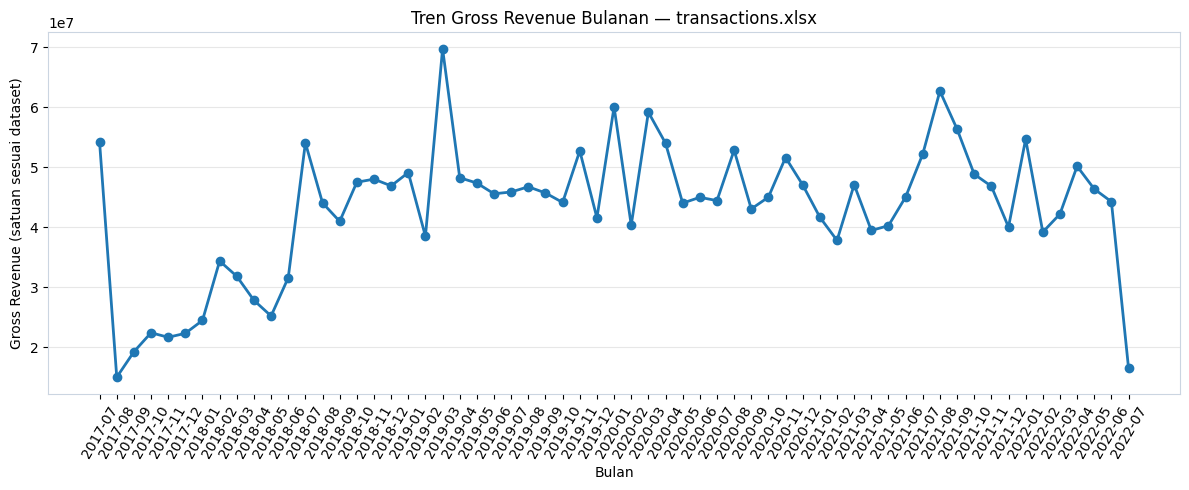

In [15]:
# EDA khusus transactions.xlsx: tren nilai transaksi per bulan

monthly_tx = (
    df_success.dropna(subset=['created_at'])
    .groupby('year_month', dropna=True)
    .agg(
        gross_revenue=('gross_amount', 'sum'),
        transaction_count=('booking_id', 'nunique'),
        active_customers=('customer_id', 'nunique')
    )
    .reset_index()
    .sort_values('year_month')
)

display(monthly_tx)

os.makedirs('Output Transactions/Charts', exist_ok=True)
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_tx['year_month'],
    monthly_tx['gross_revenue'],
    marker='o',
    linewidth=2
)
plt.title('Tren Gross Revenue Bulanan — transactions.xlsx')
plt.xlabel('Bulan')
plt.ylabel('Gross Revenue (satuan sesuai dataset)')
plt.xticks(rotation=60)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    'Output Transactions/Charts/tren_pendapatan_bulanan_transactions.png',
    dpi=200, bbox_inches='tight'
)
plt.show()

In [16]:
# Mengidentifikasi bulan dengan gross revenue tertinggi dan terendah

if not monthly_tx.empty:
    highest_month = monthly_tx.loc[monthly_tx['gross_revenue'].idxmax()]
    lowest_month = monthly_tx.loc[monthly_tx['gross_revenue'].idxmin()]

    print(f"Bulan dengan gross revenue tertinggi: {highest_month['year_month']}")
    print(f"Nilai tertinggi: {highest_month['gross_revenue']:,.2f}")
    print(f"Jumlah booking unik pada bulan tertinggi: {int(highest_month['transaction_count'])}")

    print(f"\nBulan dengan gross revenue terendah: {lowest_month['year_month']}")
    print(f"Nilai terendah: {lowest_month['gross_revenue']:,.2f}")
    print(f"Jumlah booking unik pada bulan terendah: {int(lowest_month['transaction_count'])}")
else:
    print("Tidak ada data tanggal transaksi valid untuk analisis bulanan.")

Bulan dengan gross revenue tertinggi: 2019-03
Nilai tertinggi: 69,708,190.00
Jumlah booking unik pada bulan tertinggi: 165

Bulan dengan gross revenue terendah: 2017-08
Nilai terendah: 14,977,422.00
Jumlah booking unik pada bulan terendah: 43


### Catatan Interpretasi

- **Gross revenue / gross sales value** dihitung dari perkalian kuantitas dengan harga satuan; maknanya mengikuti definisi dan satuan dalam masing-masing dataset.
- Baris dengan invoice yang diawali huruf `C` ditandai sebagai transaksi batal dan tidak dimasukkan ke analisis retail aktif.
- Biaya pengiriman (`StockCode = POST`) dikecualikan dari analisis produk agar tidak dianggap sebagai produk yang terjual.
- Data `transactions.xlsx` dan `dashboard.csv` dianalisis secara terpisah; metrik dari kedua dataset tidak boleh dijumlahkan langsung.
- Sebelum membuat rekomendasi bisnis, periksa juga retur/kuantitas negatif, nilai kosong, dan rentang tanggal hasil pemrosesan.